In [22]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt


In [23]:

# Specify the base directory containing all the action directories
base_dir = '/media/user/Dados/Important Folders/InQuant/Desenvolvimento/vulture_ai_laboratory/models/basic/'  # Replace with your base directory if different

# Initialize an empty list to store data
data_list = []
version = 'v2.0'

# Walk through the directory structure
for root, dirs, files in os.walk(base_dir):
    if root[-4:]!=version:
        continue
    for file in files:
        if file == 'report.json':
            file_path = os.path.join(root, file)
            with open(file_path, 'r') as f:
                data = json.load(f)
                # Extract necessary fields
                data_entry = {
                    'ticker': data.get('ticker'),
                    'sharpe': data.get('sharpe'),
                    'sharpe_model': data.get('sharpe_model'),
                    'max_dd': data.get('max_dd'),
                    'max_dd_model': data.get('max_dd_model')
                }
                data_list.append(data_entry)

# Create a DataFrame from the collected data
df = pd.DataFrame(data_list)

# Ensure the data types are correct
df[['sharpe', 'sharpe_model', 'max_dd', 'max_dd_model']] = df[['sharpe', 'sharpe_model', 'max_dd', 'max_dd_model']].astype(float)

# Set 'ticker' as the index
df.set_index('ticker', inplace=True)


In [24]:
df

,sharpe,sharpe_model,max_dd,max_dd_model
ticker,,,,
CMIG4.SA,1.869939,1.869939,-21.31,-21.31
FLRY3.SA,0.014705,1.358669,-29.33,-18.51
PETR3.SA,1.998553,0.000000,-34.29,0.00
PETR4.SA,2.056436,0.722261,-39.10,-7.09
PRIO3.SA,1.312295,-1.315670,-29.99,-69.08
...,...,...,...,...
MGLU3.SA,-0.970975,0.000000,-86.60,0.00
MRFG3.SA,-0.047449,-0.194359,-66.36,-28.91
MRVE3.SA,-0.138218,-1.255999,-57.23,-87.28


<Figure size 2000x1000 with 0 Axes>

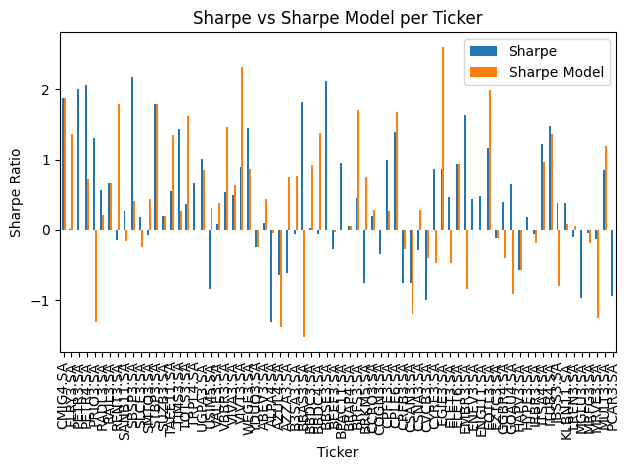

In [25]:
# Plot Sharpe ratios
plt.figure(figsize=(20,10))
df[['sharpe', 'sharpe_model']].plot(kind='bar')
plt.title('Sharpe vs Sharpe Model per Ticker')
plt.ylabel('Sharpe Ratio')
plt.xlabel('Ticker')
plt.legend(['Sharpe', 'Sharpe Model'])
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

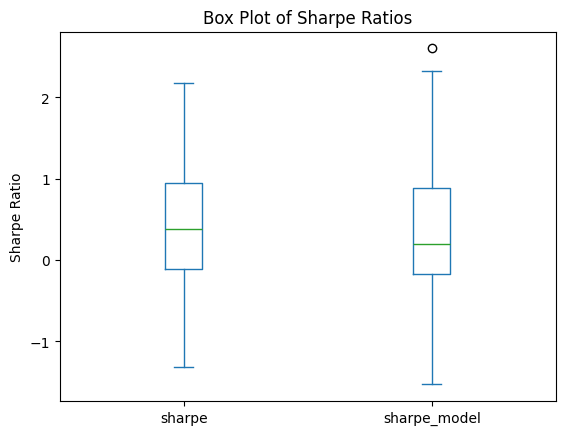

In [26]:
plt.figure(figsize=(8, 6))
df[['sharpe', 'sharpe_model']].plot(kind='box')
plt.title('Box Plot of Sharpe Ratios')
plt.ylabel('Sharpe Ratio')
plt.show()

<Figure size 1200x600 with 0 Axes>

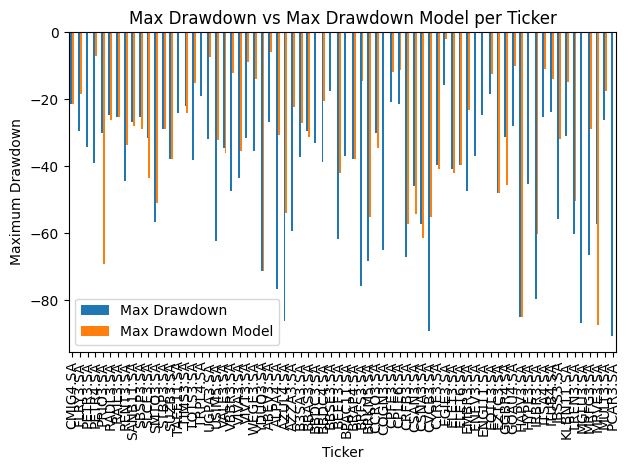

In [27]:

# Plot Max Drawdowns
plt.figure(figsize=(12, 6))
df[['max_dd', 'max_dd_model']].plot(kind='bar')
plt.title('Max Drawdown vs Max Drawdown Model per Ticker')
plt.ylabel('Maximum Drawdown')
plt.xlabel('Ticker')
plt.legend(['Max Drawdown', 'Max Drawdown Model'])
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

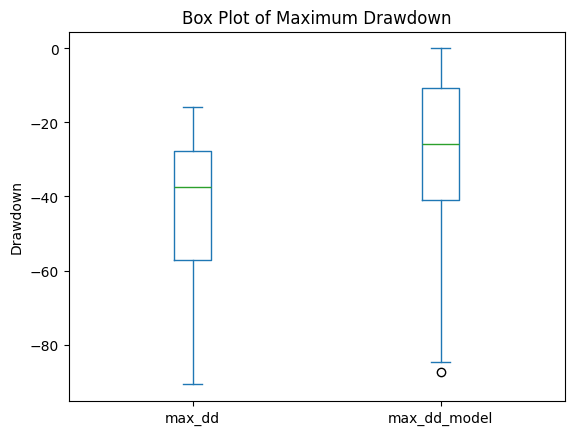

In [28]:
plt.figure(figsize=(8, 6))
df[['max_dd', 'max_dd_model']].plot(kind='box')
plt.title('Box Plot of Maximum Drawdown')
plt.ylabel('Drawdown')
plt.show()